In [3]:
import pandas as pd
import numpy as np
import datetime as dt
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load the dataset
file_path = 'ecommerce_customer_data_large.csv'
df = pd.read_csv(file_path)

In [22]:
df.info() 
df.shape
df.head() 

<class 'pandas.core.frame.DataFrame'>
Index: 148524 entries, 3 to 249999
Data columns (total 13 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   Customer_ID            148524 non-null  int64         
 1   Purchase_Date          148524 non-null  datetime64[ns]
 2   Product Category       148524 non-null  object        
 3   Product Price          148524 non-null  int64         
 4   Quantity               148524 non-null  int64         
 5   Total_Purchase_Amount  148524 non-null  int64         
 6   Payment Method         148524 non-null  object        
 7   Customer Age           148524 non-null  int64         
 8   Returns                101142 non-null  float64       
 9   Customer Name          148524 non-null  object        
 10  Age                    148524 non-null  int64         
 11  Gender                 148524 non-null  object        
 12  Churn                  148524 non-null  int64    

,Customer_ID,Purchase_Date,Product Category,Product Price,Quantity,Total_Purchase_Amount,Payment Method,Customer Age,Returns,Customer Name,Age,Gender,Churn
3,44605,2023-01-17 13:14:36,Electronics,396,3,937,Cash,31,0.0,John Rivera,31,Female,0
6,13738,2023-07-25 05:17:24,Electronics,205,1,2773,Credit Card,27,NaN,Lauren Johnson,27,Female,0
8,13738,2021-12-21 03:29:05,Home,12,2,2175,Cash,27,NaN,Lauren Johnson,27,Female,0
9,13738,2023-02-09 00:53:14,Electronics,40,4,4327,Cash,27,0.0,Lauren Johnson,27,Female,0
10,33969,2023-02-28 19:58:23,Clothing,410,3,5018,Credit Card,27,NaN,Carol Allen,27,Male,0


In [23]:
df.nunique()

Customer_ID               47490
Purchase_Date            148419
Product Category              4
Product Price               491
Quantity                      5
Total_Purchase_Amount      5235
Payment Method                3
Customer Age                 53
Returns                       1
Customer Name             38373
Age                          53
Gender                        2
Churn                         2
dtype: int64

Data Preprocessing

In [24]:
df[df.duplicated(keep=False)] 

,Customer_ID,Purchase_Date,Product Category,Product Price,Quantity,Total_Purchase_Amount,Payment Method,Customer Age,Returns,Customer Name,Age,Gender,Churn


In [4]:
df.isnull().sum()


Customer ID                  0
Purchase Date                0
Product Category             0
Product Price                0
Quantity                     0
Total Purchase Amount        0
Payment Method               0
Customer Age                 0
Returns                  47382
Customer Name                0
Age                          0
Gender                       0
Churn                        0
dtype: int64

In [5]:
df.shape

(250000, 13)

In [6]:
df = df[df["Returns"] != 1.000]

RFM Analysis is a technique used for customer segmentation.
It allows grouping customers based on their purchase behavior, enabling the development of strategies for each group.
Recency (How recently a customer has made a purchase)
Frequency (How often a customer makes purchases)
Monetary (How much money a customer spends)¶

In [7]:
df["Purchase Date"].max()


'2023-09-13 18:42:49'

<class 'pandas.core.frame.DataFrame'>
Index: 148524 entries, 3 to 249999
Data columns (total 13 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   Customer_ID            148524 non-null  int64         
 1   Purchase_Date          148524 non-null  datetime64[ns]
 2   Product Category       148524 non-null  object        
 3   Product Price          148524 non-null  int64         
 4   Quantity               148524 non-null  int64         
 5   Total_Purchase_Amount  148524 non-null  int64         
 6   Payment Method         148524 non-null  object        
 7   Customer Age           148524 non-null  int64         
 8   Returns                101142 non-null  float64       
 9   Customer Name          148524 non-null  object        
 10  Age                    148524 non-null  int64         
 11  Gender                 148524 non-null  object        
 12  Churn                  148524 non-null  int64    

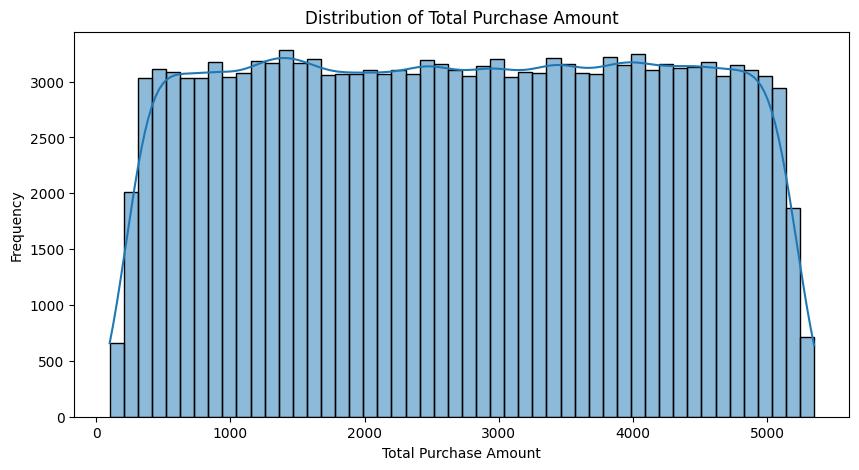

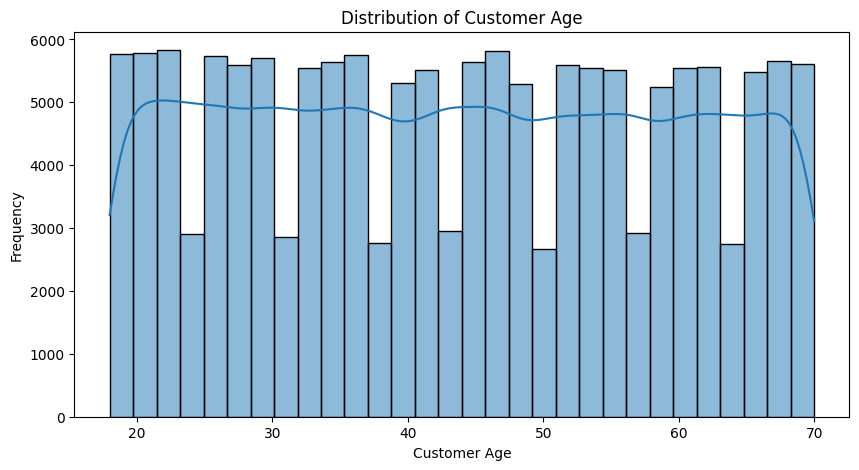

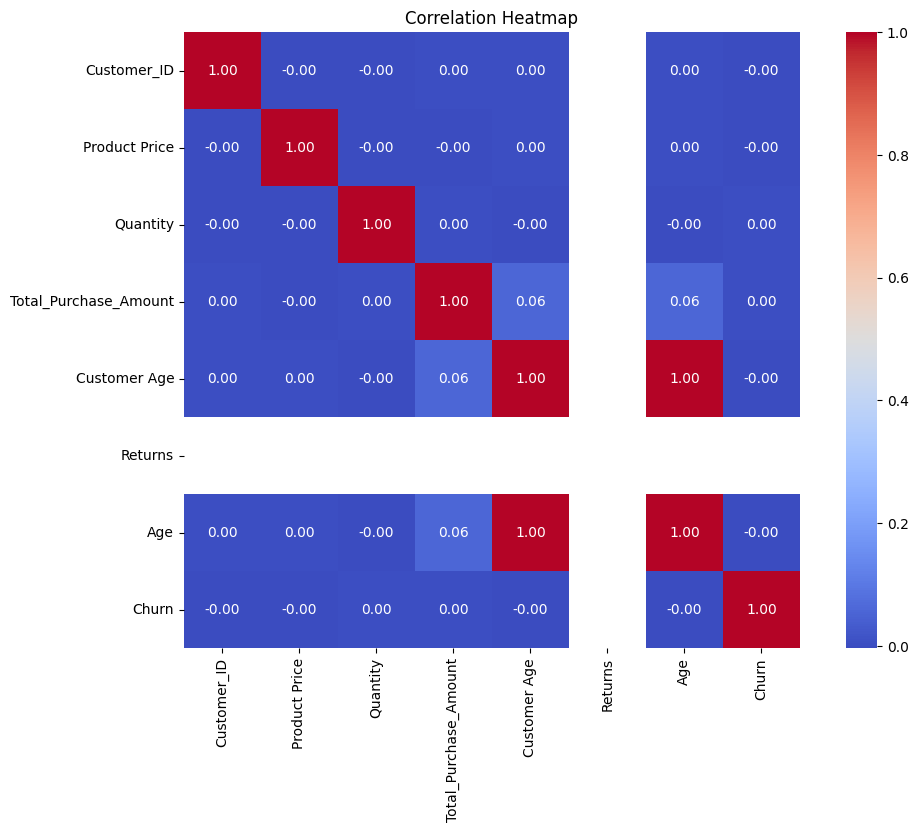

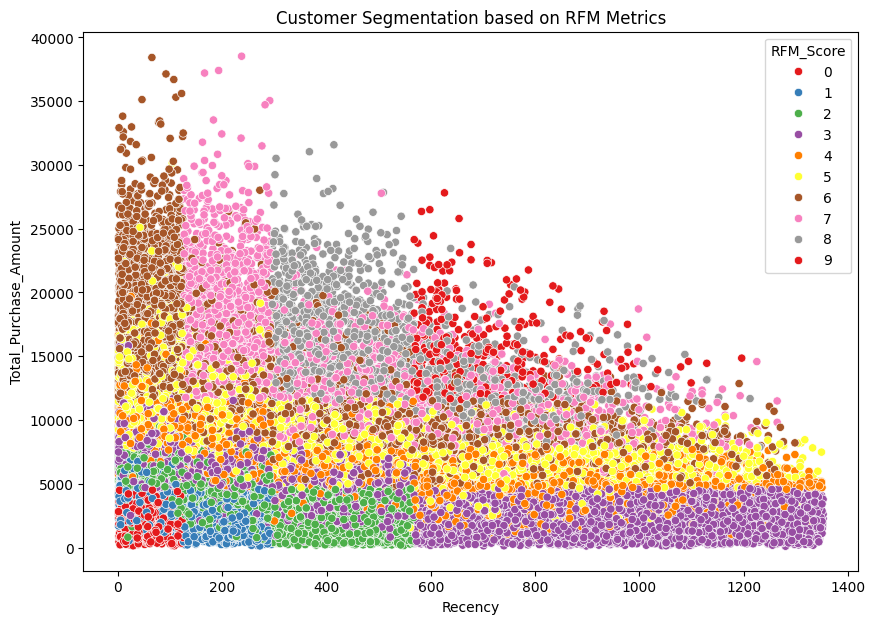

   RFM_Score     Recency  Frequency  Total_Purchase_Amount
0          0   61.772004   3.337222            2718.963945
1          1  139.196035   4.402643            3626.610132
2          2  250.193640   5.222609            4430.329340
3          3  560.099008   5.326371            4658.253577
4          4  407.566696   7.887247            7268.051854
5          5  376.759937  10.114750            9346.317576
6          6  295.697720  14.102358           12999.450246
7          7  371.193063  15.400087           14118.947426
8          8  497.360599  16.559102           15023.851372
9          9  703.947644  17.091623           15322.746073


In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



# Step 1: Data Overview
print(df.info())
print(df.describe())
print("Missing values:\n", df.isnull().sum())

# Step 2: Univariate Analysis
# Distribution of Total Purchase Amount
plt.figure(figsize=(10, 5))
sns.histplot(df['Total_Purchase_Amount'], bins=50, kde=True)
plt.title('Distribution of Total Purchase Amount')
plt.xlabel('Total Purchase Amount')
plt.ylabel('Frequency')
plt.show()

# Distribution of Customer Age
plt.figure(figsize=(10, 5))
sns.histplot(df['Customer Age'], bins=30, kde=True)
plt.title('Distribution of Customer Age')
plt.xlabel('Customer Age')
plt.ylabel('Frequency')
plt.show()

# Step 3: Bivariate Analysis
# Correlation heatmap
numeric_df = df.select_dtypes(include=['number'])  # Select only numeric columns
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title('Correlation Heatmap')
plt.show()

# Step 4: Customer Segmentation (RFM Metrics)
# Convert Purchase Date to datetime if not already done
df['Purchase_Date'] = pd.to_datetime(df['Purchase_Date'])

# Calculate Recency, Frequency, and Monetary
today_date = pd.to_datetime('2023-09-15')
rfm = df.groupby('Customer_ID').agg({
    'Purchase_Date': lambda x: (today_date - x.max()).days,
    'Quantity': 'sum',
    'Total_Purchase_Amount': 'sum'
}).reset_index()

rfm.rename(columns={'Purchase_Date': 'Recency', 'Quantity': 'Frequency'}, inplace=True)

# Step 5: Segmentation Analysis
# Create segments based on RFM scores
rfm['RFM_Score'] = pd.qcut(rfm['Recency'], 4, labels=False) + pd.qcut(rfm['Frequency'], 4, labels=False) + pd.qcut(rfm['Total_Purchase_Amount'], 4, labels=False)

# Visualize clusters
plt.figure(figsize=(10, 7))
sns.scatterplot(data=rfm, x='Recency', y='Total_Purchase_Amount', hue='RFM_Score', palette='Set1')
plt.title('Customer Segmentation based on RFM Metrics')
plt.show()

# Step 6: Insights and Recommendations
# Summary of RFM segments
segment_summary = rfm.groupby('RFM_Score').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Total_Purchase_Amount': 'mean'
}).reset_index()
print(segment_summary)


In [8]:
df = df.rename(columns={"Purchase Date": "Purchase_Date"})
df = df.rename(columns={"Customer ID": "Customer_ID"})
df = df.rename(columns={"Total Purchase Amount": "Total_Purchase_Amount"})
df['Purchase_Date'] = pd.to_datetime(df['Purchase_Date'])
today_date = dt.datetime(2023, 9, 15)

In [9]:
rfm = df.groupby('Customer_ID').agg({'Purchase_Date': lambda Purchase_Date: (today_date - Purchase_Date.max()).days,
                                     'Customer_ID': lambda Customer_ID: Customer_ID.value_counts(),
                                     'Total_Purchase_Amount': lambda Total_Purchase_Amount: Total_Purchase_Amount.sum()})
rfm

,Purchase_Date,Customer_ID,Total_Purchase_Amount
Customer_ID,,,
1,289,3,6290
2,141,2,5381
3,223,4,9423
4,687,2,1252
5,425,2,2088
...,...,...,...
49996,360,5,13750
49997,389,2,5714
49998,117,4,3599


In [10]:
rfm.columns = ['Recency', 'Frequency', 'Monetary']

In [11]:
rfm["recency_score"] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1])

# 0-100, 0-20, 20-40, 40-60, 60-80, 80-100

rfm["frequency_score"] = pd.qcut(rfm['Frequency'].rank(method="first"), 5, labels=[1, 2, 3, 4, 5])

rfm["monetary_score"] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5])

rfm["RFM_SCORE"] = (rfm['recency_score'].astype(str) +
                    rfm['frequency_score'].astype(str))

In [12]:
rfm.head()

,Recency,Frequency,Monetary,recency_score,frequency_score,monetary_score,RFM_SCORE
Customer_ID,,,,,,,
1,289,3,6290,3,2,2,32
2,141,2,5381,4,1,2,41
3,223,4,9423,3,4,4,34
4,687,2,1252,1,1,1,11
5,425,2,2088,2,1,1,21


In [13]:
seg_map = {
    r'[1-2][1-2]': 'Hibernating',
    r'[1-2][3-4]': 'At Risk',
    r'[1-2]5': 'Cant Loose',
    r'3[1-2]': 'About to sleep',
    r'33': 'Need Attention',
    r'[3-4][4-5]': 'Loyal Customers',
    r'41': 'Promising',
    r'51': 'New Customers',
    r'[4-5][2-3]': 'Potential Loyalists',
    r'5[4-5]': 'Champions'
}

In [14]:
rfm['segment'] = rfm['RFM_SCORE'].replace(seg_map, regex=True)

In [15]:
rfm

,Recency,Frequency,Monetary,recency_score,frequency_score,monetary_score,RFM_SCORE,segment
Customer_ID,,,,,,,,
1,289,3,6290,3,2,2,32,About to sleep
2,141,2,5381,4,1,2,41,Promising
3,223,4,9423,3,4,4,34,Loyal Customers
4,687,2,1252,1,1,1,11,Hibernating
5,425,2,2088,2,1,1,21,Hibernating
...,...,...,...,...,...,...,...,...
49996,360,5,13750,3,5,5,35,Loyal Customers
49997,389,2,5714,2,2,2,22,Hibernating
49998,117,4,3599,4,5,1,45,Loyal Customers


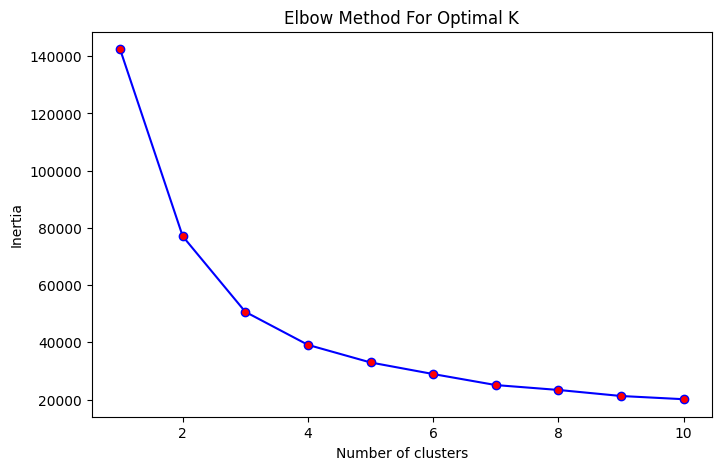

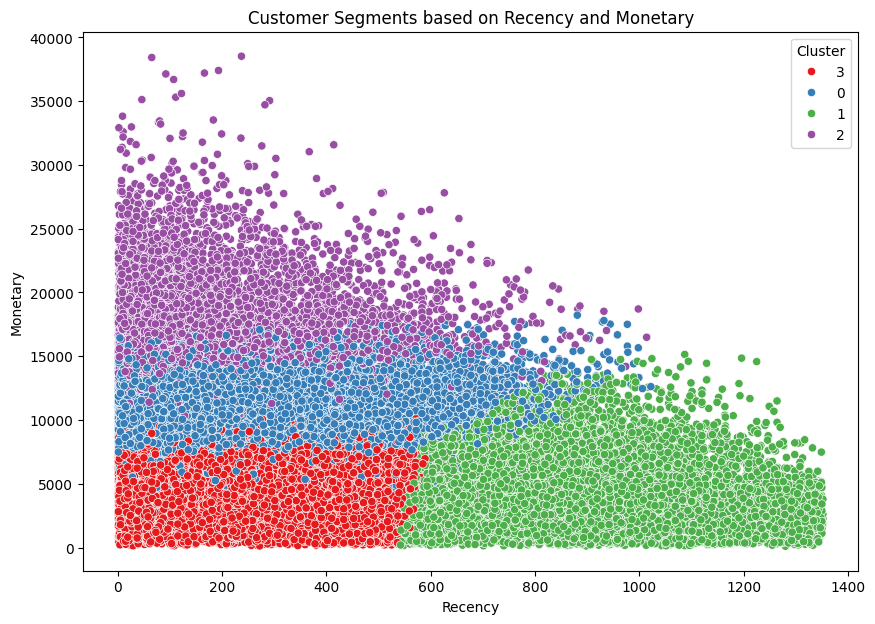

  Cluster     Recency  Frequency      Monetary
0       0  258.119557   3.837631  10641.097078
1       1  878.472786   1.759364   4645.350761
2       2  188.753051   5.998876  17682.900128
3       3  258.250494   2.075121   4978.689845


In [16]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'rfm' is the DataFrame with Recency, Frequency, and Monetary features
# Step 1: Preprocessing - Scaling the data
features = ['Recency', 'Frequency', 'Monetary']
X = rfm[features]

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 2: Determine the optimal number of clusters using the Elbow method
inertia = []
K = range(1, 11)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot the Elbow method
plt.figure(figsize=(8, 5))
plt.plot(K, inertia, 'bo-', markerfacecolor='r')
plt.title('Elbow Method For Optimal K')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.show()

# Step 3: Fit K-Means with the optimal number of clusters (let's assume K=4 based on the elbow plot)
kmeans = KMeans(n_clusters=4, random_state=42)
rfm['Cluster'] = kmeans.fit_predict(X_scaled)

# Step 4: Analyze the clusters
rfm['Cluster'] = rfm['Cluster'].astype(str)  # Convert cluster labels to string for easier visualization
plt.figure(figsize=(10, 7))
sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Cluster', palette='Set1')
plt.title('Customer Segments based on Recency and Monetary')
plt.show()

# Step 5: Interpretation - View cluster means to understand segments
cluster_summary = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).reset_index()

print(cluster_summary)


Silhouette Score: 0.340
Davies-Bouldin Index: 0.949


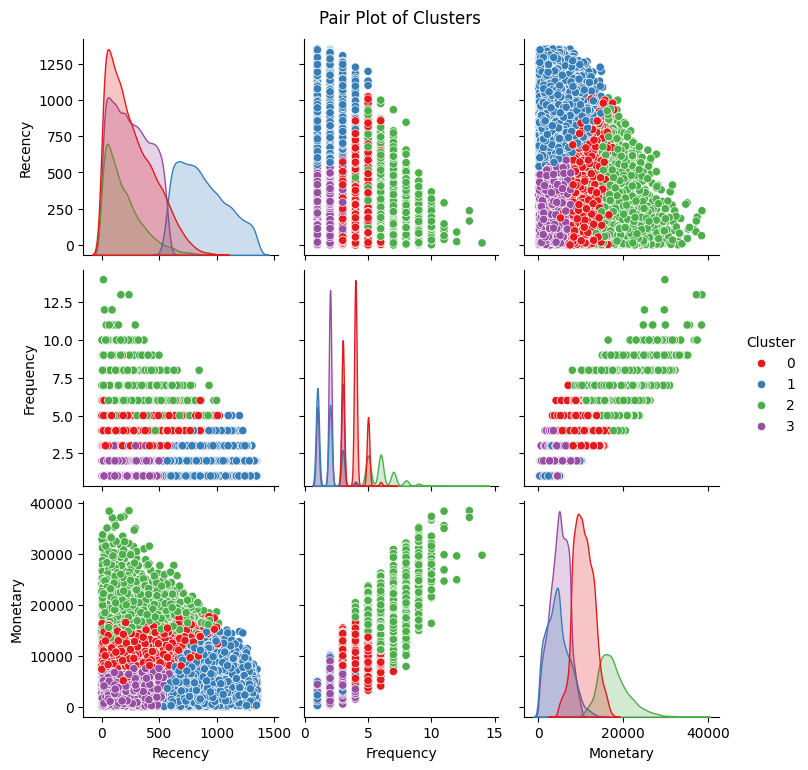

In [17]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
import matplotlib.pyplot as plt
import seaborn as sns

rfm['Cluster'] = rfm['Cluster'].astype(int)

silhouette_avg = silhouette_score(X_scaled, rfm['Cluster'])
davies_bouldin_avg = davies_bouldin_score(X_scaled, rfm['Cluster'])

print(f'Silhouette Score: {silhouette_avg:.3f}')
print(f'Davies-Bouldin Index: {davies_bouldin_avg:.3f}')

# Step 3: Visualize clusters with Pair Plot for detailed analysis
sns.pairplot(rfm, hue='Cluster', vars=features, palette='Set1')
plt.suptitle('Pair Plot of Clusters', y=1.02)
plt.show()

Business Model

In [17]:
rfm.head()

,Recency,Frequency,Monetary,recency_score,frequency_score,monetary_score,RFM_SCORE,segment,Cluster
Customer_ID,,,,,,,,,
1,289,3,6290,3,2,2,32,About to sleep,3
2,141,2,5381,4,1,2,41,Promising,3
3,223,4,9423,3,4,4,34,Loyal Customers,0
4,687,2,1252,1,1,1,11,Hibernating,1
5,425,2,2088,2,1,1,21,Hibernating,3


In [18]:
# Assuming rfm DataFrame is already defined in your previous notebook

# Check the data type of the 'Cluster' column
print("Initial Cluster Data Type:", rfm['Cluster'].dtype)

# If it's not an integer type, convert it
if rfm['Cluster'].dtype == 'object':
    rfm['Cluster'] = rfm['Cluster'].astype(int)

# Confirm the data types of the DataFrame
print("Data Types After Conversion:\n", rfm.dtypes)

# Function to assign business strategy and customer characteristics based on cluster
def assign_business_strategy(row):
    if row['Cluster'] == 0:  # Loyal Champions (Cluster 0)
        return (
            "Highly engaged, made recent purchases, high spending.",
            [
                "Offer loyalty rewards (e.g., VIP programs, early access to new products).",
                "Introduce referral programs to encourage bringing in new customers.",
                "Provide exclusive discounts or personalized product recommendations."
            ]
        )
    elif row['Cluster'] == 1:  # At Risk (Cluster 1)
        return (
            "Haven't made a purchase recently but were frequent buyers.",
            [
                "Launch a re-engagement campaign with personalized offers and incentives.",
                "Use email marketing to highlight new arrivals or special deals to win them back.",
                "Offer time-sensitive discounts to create urgency and bring them back."
            ]
        )
    elif row['Cluster'] == 2:  # New & Promising (Cluster 2)
        return (
            "New customers, recent engagement, low purchase frequency.",
            [
                "Focus on nurturing these customers through welcome offers or first-time buyer discounts.",
                "Provide a personalized shopping experience to encourage repeat purchases.",
                "Send follow-up emails or push notifications to keep them engaged."
            ]
        )
    elif row['Cluster'] == 3:  # Hibernating Customers (Cluster 3)
        return (
            "Low purchase frequency, haven't bought anything in a long time.",
            [
                "Allocate minimal marketing resources to this segment.",
                "Send occasional newsletters or low-investment offers (e.g., free shipping) to reawaken interest."
            ]
        )
    # Default return in case no match found
    return (
        "Unknown",
        ["No specific strategy assigned."]
    )

# Apply the strategy assignment function to each row of the rfm DataFrame
rfm[['Customer_Characteristics', 'Business_Strategy_List']] = rfm.apply(
    lambda row: pd.Series(assign_business_strategy(row)), axis=1
)

# Display relevant columns to verify the results
print(rfm[['Cluster', 'Customer_Characteristics', 'Business_Strategy_List']])

# Debugging output to ensure clusters are processed correctly
for i, row in rfm.iterrows():
    print(f"Row {i}: Cluster = {row['Cluster']}, Characteristics = {row['Customer_Characteristics']}, Strategy = {row['Business_Strategy_List']}")


Initial Cluster Data Type: int64
Data Types After Conversion:
 Recency               int64
Frequency             int64
Monetary              int64
recency_score      category
frequency_score    category
monetary_score     category
RFM_SCORE            object
segment              object
Cluster               int64
dtype: object
             Cluster                           Customer_Characteristics  \
Customer_ID                                                               
1                  3  Low purchase frequency, haven't bought anythin...   
2                  3  Low purchase frequency, haven't bought anythin...   
3                  0  Highly engaged, made recent purchases, high sp...   
4                  1  Haven't made a purchase recently but were freq...   
5                  3  Low purchase frequency, haven't bought anythin...   
...              ...                                                ...   
49996              0  Highly engaged, made recent purchases, high sp...

In [19]:
rfm.head()

,Recency,Frequency,Monetary,recency_score,frequency_score,monetary_score,RFM_SCORE,segment,Cluster,Customer_Characteristics,Business_Strategy_List
Customer_ID,,,,,,,,,,,
1,289,3,6290,3,2,2,32,About to sleep,3,"Low purchase frequency, haven't bought anythin...",[Allocate minimal marketing resources to this ...
2,141,2,5381,4,1,2,41,Promising,3,"Low purchase frequency, haven't bought anythin...",[Allocate minimal marketing resources to this ...
3,223,4,9423,3,4,4,34,Loyal Customers,0,"Highly engaged, made recent purchases, high sp...","[Offer loyalty rewards (e.g., VIP programs, ea..."
4,687,2,1252,1,1,1,11,Hibernating,1,Haven't made a purchase recently but were freq...,[Launch a re-engagement campaign with personal...
5,425,2,2088,2,1,1,21,Hibernating,3,"Low purchase frequency, haven't bought anythin...",[Allocate minimal marketing resources to this ...


In [20]:
import dash
from dash import dcc, html, Input, Output
import pandas as pd
import plotly.express as px

# Assuming 'rfm' is your RFM DataFrame
# Sample DataFrame creation for demonstration
# Replace this with your actual RFM DataFrame
# rfm = pd.read_csv('path_to_your_rfm_data.csv')

# Initialize the Dash app
app = dash.Dash(__name__)

# Layout of the Dashboard
app.layout = html.Div([
    html.H1("Customer Segmentation Dashboard"),
    
    dcc.Dropdown(
        id='cluster-dropdown',
        options=[{'label': f'Cluster {i}', 'value': i} for i in rfm['Cluster'].unique()],
        value=rfm['Cluster'].unique()[0],  # Default value
        multi=False,
        placeholder='Select a Cluster'
    ),
    
    dcc.Graph(id='cluster-summary'),
    
    dcc.Graph(id='recency-frequency'),
    
    dcc.Graph(id='monetary-analysis')
])

# Callback to update cluster summary
@app.callback(
    Output('cluster-summary', 'figure'),
    Input('cluster-dropdown', 'value')
)
def update_cluster_summary(selected_cluster):
    filtered_rfm = rfm[rfm['Cluster'] == selected_cluster]
    summary = filtered_rfm.groupby('Cluster').agg({
        'Recency': 'mean',
        'Frequency': 'mean',
        'Monetary': 'mean'
    }).reset_index()

    fig = px.bar(summary, x='Cluster', 
                 y=['Recency', 'Frequency', 'Monetary'],
                 title=f'Cluster Summary for Cluster {selected_cluster}',
                 barmode='group')
    return fig

# Callback to update recency-frequency scatter plot
@app.callback(
    Output('recency-frequency', 'figure'),
    Input('cluster-dropdown', 'value')
)
def update_recency_frequency(selected_cluster):
    filtered_rfm = rfm[rfm['Cluster'] == selected_cluster]
    fig = px.scatter(filtered_rfm, x='Recency', y='Frequency', color='Cluster',
                     title=f'Recency vs Frequency for Cluster {selected_cluster}')
    return fig

# Callback to update monetary analysis
@app.callback(
    Output('monetary-analysis', 'figure'),
    Input('cluster-dropdown', 'value')
)
def update_monetary_analysis(selected_cluster):
    filtered_rfm = rfm[rfm['Cluster'] == selected_cluster]
    fig = px.histogram(filtered_rfm, x='Monetary', title=f'Monetary Distribution for Cluster {selected_cluster}')
    return fig

# Run the app
if __name__ == '__main__':
    app.run_server(debug=True)


In [21]:
import dash
from dash import dcc, html, Input, Output
import pandas as pd
import plotly.express as px

# Assuming 'rfm' is your RFM DataFrame
# Sample DataFrame creation for demonstration
# Replace this with your actual RFM DataFrame
# rfm = pd.read_csv('path_to_your_rfm_data.csv')

# Initialize the Dash app
app = dash.Dash(__name__)

# Layout of the Dashboard
app.layout = html.Div([
    html.H1("Customer Segmentation Dashboard"),
    
    dcc.Graph(id='cluster-summary'),
    
    dcc.Graph(id='recency-frequency'),
    
    dcc.Graph(id='monetary-analysis'),
    
    html.Div([
        html.H2("Cluster Means"),
        dcc.Graph(id='cluster-means')
    ])
])

# Callback to update cluster summary
@app.callback(
    Output('cluster-summary', 'figure'),
    Input('cluster-summary', 'id')
)
def update_cluster_summary(_):
    # Calculate summary statistics for all clusters
    summary = rfm.groupby('Cluster').agg({
        'Recency': 'mean',
        'Frequency': 'mean',
        'Monetary': 'mean'
    }).reset_index()

    fig = px.bar(summary, x='Cluster', 
                 y=['Recency', 'Frequency', 'Monetary'],
                 title='Cluster Summary',
                 barmode='group', 
                 labels={'value': 'Mean Value', 'variable': 'Metrics'},
                 height=400)
    return fig

# Callback to update recency-frequency scatter plot
@app.callback(
    Output('recency-frequency', 'figure'),
    Input('recency-frequency', 'id')
)
def update_recency_frequency(_):
    fig = px.scatter(rfm, x='Recency', y='Frequency', color='Cluster',
                     title='Recency vs Frequency',
                     hover_data=['Monetary'],
                     labels={'Recency': 'Recency (Days)', 'Frequency': 'Frequency (Count)'},
                     height=400)
    return fig

# Callback to update monetary analysis
@app.callback(
    Output('monetary-analysis', 'figure'),
    Input('monetary-analysis', 'id')
)
def update_monetary_analysis(_):
    fig = px.histogram(rfm, x='Monetary', color='Cluster', 
                       title='Monetary Distribution by Cluster',
                       labels={'Monetary': 'Monetary Value'},
                       height=400)
    return fig

# Callback to update cluster means visualization
@app.callback(
    Output('cluster-means', 'figure'),
    Input('cluster-means', 'id')
)
def update_cluster_means(_):
    # Calculate mean values for the clusters
    cluster_means = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean().reset_index()
    cluster_means_melted = cluster_means.melt(id_vars='Cluster', var_name='Metrics', value_name='Mean Value')

    fig = px.line(cluster_means_melted, x='Cluster', y='Mean Value', color='Metrics',
                  title='Mean Recency, Frequency, and Monetary by Cluster',
                  labels={'Mean Value': 'Mean Value'},
                  height=400)
    return fig

# Run the app
if __name__ == '__main__':
    app.run_server(debug=True)
